# Describe: profile and quality report of the final table

Input: `merged_clean.csv`, written by `merge.ipynb` (Phase B). This notebook **changes no value and writes no file**: it only describes the table that the analysis uses.

- **Profile:** where the rows come from, column types, missing values, the main numbers and categories, the dates covered.
- **Quality report:** how many rows each cleaning step touched, split into values changed, ESTIMATES, and values kept but marked.
- **At the end:** which rows and filters to use in the analysis.

Run it with Restart & Run All, after the three notebooks of Phases A and B.

In [1]:
import pandas as pd

df = pd.read_csv("../data/processed/merged_clean.csv",
                 parse_dates=["arrival_date", "reservation_status_date", "record_updated_at"])
print("rows, columns:", df.shape)
print("booking_id unique:", df["booking_id"].is_unique)
df.head(3)

rows, columns: (25000, 68)
booking_id unique: True


,booking_id,hotel,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,status_from_pms,nights_conflict,status_date_from_pms,price_inflated,week_nights_from_crm,week_nights_estimated,adr_from_crm,adr_estimated,price_from_pms,repeated_inconsistent
0,BK300001,Resort Hotel,2016,6,26,2.0,5.0,3.0,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False
1,BK300002,Resort Hotel,2016,7,23,2.0,5.0,2.0,1.0,0.0,...,False,False,False,False,False,False,False,False,False,False
2,BK300003,City Hotel,2016,10,20,0.0,3.0,1.0,0.0,0.0,...,False,False,False,False,False,False,False,False,False,False


## 1. Where the rows come from

The merge is an outer merge on the booking code, so a row can come from both files or from only one. `in_pms` and `in_crm` say which.

In [2]:
pd.crosstab(df["in_pms"], df["in_crm"], margins=True)

in_crm,False,True,All
in_pms,,,
False,0,750,750
True,500,23750,24250
All,500,24500,25000


23,750 bookings are in both files, 500 only in the PMS and 750 only in the CRM. This explains most of the missing values below: a row that is only in the CRM has no PMS columns, and the other way round.

## 2. Columns and types

The 68 columns are of four kinds:
- **shared**, filled from both files: `booking_id`, `hotel`, `arrival_date`, `adults`, `is_canceled`;
- **PMS only**: rooms, meal, nights, adr, special requests, deposit type…;
- **CRM only**: lead time, country, segment, channel, customer type, status, total price…;
- **flags** (True/False): which rows each cleaning step touched, plus `in_pms` and `in_crm`.

In [3]:
print(df.dtypes.value_counts())

bool              32
float64           19
object            11
int64              3
datetime64[ns]     3
Name: count, dtype: int64


In [4]:
shared = ["booking_id", "hotel", "arrival_date", "arrival_date_year", "arrival_date_month",
          "arrival_date_day_of_month", "adults", "is_canceled"]
flags = list(df.select_dtypes("bool").columns)
pms_cols = list(df.loc[:, "stays_in_weekend_nights":"record_updated_at"].columns)
pms_cols.remove("adults")
pms_cols.remove("is_canceled")
crm_cols = list(df.loc[:, "n_adults":"total_price"].columns)
print("shared:", len(shared), "| PMS only:", len(pms_cols), "| CRM only:", len(crm_cols), "| flags:", len(flags))

shared: 8 | PMS only: 13 | CRM only: 15 | flags: 32


## 3. Missing values

A missing value can mean two different things: the booking is not in the file that has that column (**structural**), or the file has the booking but not the value (**real gap**). We count them separately.

In [5]:
missing = df.isna().sum()
structural = pd.concat([df.loc[~df["in_pms"], pms_cols].isna().sum(),
                        df.loc[~df["in_crm"], crm_cols].isna().sum()])
report = pd.DataFrame({"missing": missing, "structural": structural})
report["structural"] = report["structural"].fillna(0).astype(int)
report["real gap"] = report["missing"] - report["structural"]
report = report[report["missing"] > 0].sort_values("real gap", ascending=False)
print("shared columns with missing values:", missing[shared].sum())
report

shared columns with missing values: 9


,missing,structural,real gap
company_id,23624,500,23124
agent_id,3800,500,3300
children,1559,750,809
meal,1469,750,719
n_adults,744,500,244
guest_country,614,500,114
lead_time_days,525,500,25
total_price,524,500,24
adr,760,750,10
adults,9,0,9


**What the table says**

- The **shared columns are complete** except `adults` (9 rows): every booking has a hotel, an arrival date and a cancellation status.
- **Structural gaps:** 750 on PMS columns and 500 on CRM columns. They are not errors.
- **Real gaps that matter:**
  - `company_id` and `agent_id` are empty when a booking has no company or no agent: that is information, not a gap;
  - `children` (809) are missing in the City Hotel and were left empty on purpose (see `pms_cleaning.ipynb`);
  - `meal` (719): 483 missing and 236 `Undefined`, which is not a meal plan;
  - `n_adults` (244), `guest_country` (114), `lead_time_days` (25), `total_price` (24), `distribution_channel` (3), `market_segment` (2): CRM values that were empty or impossible (`unknown`, `9999`, `Undefined`);
  - `adr` (10) and `stays_in_week_nights` (2): no source in either file could rebuild them.

## 4. Main numbers

`describe()` on the columns used most in the analysis. The prices are described twice: on all rows, and only on the rows that are valid for price analyses (price above 0, at least one night, not the flagged outlier).

In [6]:
numbers = ["lead_time_days", "adr", "total_price", "stays_in_weekend_nights", "stays_in_week_nights",
           "adults", "children", "babies", "total_of_special_requests", "booking_changes"]
df[numbers].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
lead_time_days,24475.0,103.7,106.0,0.0,18.0,70.0,160.0,737.0
adr,24240.0,102.0,58.5,0.0,69.1,94.7,126.0,5400.0
total_price,24476.0,357.9,335.1,0.0,147.6,268.6,448.2,5400.0
stays_in_weekend_nights,24250.0,0.9,1.0,0.0,0.0,1.0,2.0,13.0
stays_in_week_nights,24248.0,2.5,1.8,0.0,1.0,2.0,3.0,32.0
adults,24991.0,1.9,0.6,0.0,2.0,2.0,2.0,55.0
children,23441.0,0.1,0.4,0.0,0.0,0.0,0.0,3.0
babies,24250.0,0.0,0.1,0.0,0.0,0.0,0.0,2.0
total_of_special_requests,24250.0,0.6,0.8,0.0,0.0,0.0,1.0,5.0
booking_changes,24250.0,0.2,0.6,0.0,0.0,0.0,0.0,18.0


In [7]:
nights = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
price_ok = (df["adr"] > 0) & (nights > 0) & ~df["adr_outlier"]
print("rows valid for price analyses:", price_ok.sum(), "of", len(df))
df.loc[price_ok, ["adr", "total_price"]].describe().round(1).T

rows valid for price analyses: 23856 of 25000


,count,mean,std,min,25%,50%,75%,max
adr,23856.0,103.4,46.2,1.0,70.9,95.0,126.2,387.0
total_price,23373.0,363.5,333.5,2.0,151.0,270.0,452.8,4141.2


**What the numbers say**

- On all rows the adr goes from 0 to 5,400: the 0s are the 381 free or unpriced bookings, and 5,400 is the one flagged outlier (`adr_outlier`). On the valid rows the mean is 103.4 euro and the maximum 387.
- The maximum of 55 adults is a `Group` booking that both files confirm (`adults_over_10`); the median booking is 2 adults, no children.
- The lead time goes from 0 to 737 days, with a median of 70: half of the bookings are made more than two months ahead.

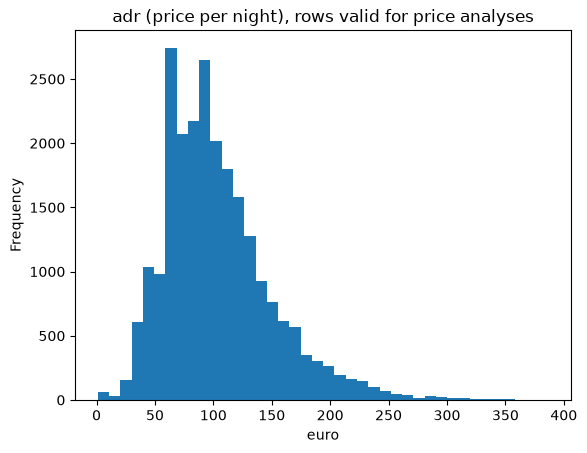

In [8]:
ax = df.loc[price_ok, "adr"].plot(kind="hist", bins=40, title="adr (price per night), rows valid for price analyses")
ax.set_xlabel("euro");

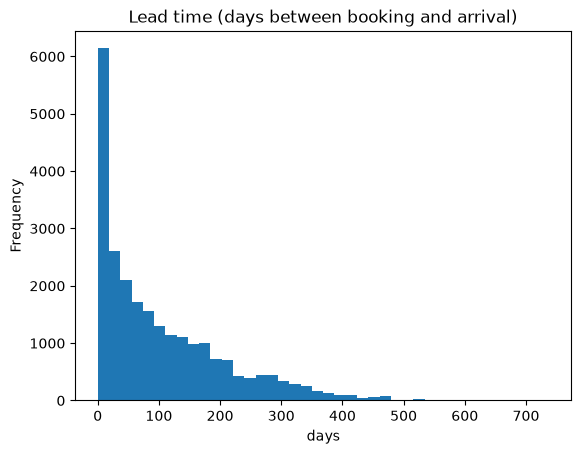

In [9]:
ax = df["lead_time_days"].plot(kind="hist", bins=40, title="Lead time (days between booking and arrival)")
ax.set_xlabel("days");

## 5. Categories

In [10]:
for col in ["hotel", "deposit_type", "market_segment", "distribution_channel", "customer_type",
            "meal", "reservation_status"]:
    print(df[col].value_counts(dropna=False), end="\n\n")

hotel
City Hotel      16621
Resort Hotel     8379
Name: count, dtype: int64

deposit_type
No Deposit    21293
Non Refund     2924
NaN             750
Refundable       33
Name: count, dtype: int64

market_segment
Online TA        11737
Offline TA/TO     4907
Groups            4071
Direct            2504
Corporate         1090
NaN                502
Complementary      142
Aviation            47
Name: count, dtype: int64

distribution_channel
TA/TO        20140
Direct        2905
Corporate     1402
NaN            503
GDS             50
Name: count, dtype: int64

customer_type
Transient          18421
Transient-Party     5164
Contract             818
NaN                  500
Group                 97
Name: count, dtype: int64

meal
BB     18423
HB      2853
SC      2092
NaN     1469
FB       163
Name: count, dtype: int64

reservation_status
Check-Out    15376
Canceled      8868
NaN            500
No-Show        256
Name: count, dtype: int64



In [11]:
print("countries:", df["guest_country"].nunique())
df["guest_country"].value_counts().head(10)

countries: 125


guest_country
PRT    9920
GBR    2563
FRA    2187
ESP    1738
DEU    1478
ITA     743
IRL     708
BEL     463
BRA     445
USA     427
Name: count, dtype: int64

## 6. Dates covered

In [12]:
print("arrival from", df["arrival_date"].min().date(), "to", df["arrival_date"].max().date())
print(df["arrival_date"].dt.year.value_counts().sort_index())
pd.crosstab(df["arrival_date"].dt.year, df["hotel"])

arrival from 2015-07-01 to 2017-08-31
arrival_date
2015     4531
2016    12006
2017     8463
Name: count, dtype: int64


hotel,City Hotel,Resort Hotel
arrival_date,,
2015,2803,1728
2016,8086,3920
2017,5732,2731


The data start in July 2015 and end in August 2017: **2015 and 2017 are partial years**, and only 2016 is complete. The City Hotel has about two bookings out of three in every year. Comparing yearly totals would be wrong; to compare years we use the same months (January to August).

## 7. Quality report: what the cleaning touched

Every cleaning step created a flag column before changing a value. We group the 30 cleaning flags by what happened to the value:
- **changed**: set to NaN because impossible, recomputed with a formula, or taken from the other file;
- **ESTIMATE**: a fill that is plausible but not proven;
- **kept, only marked**: the value is unchanged; the flag marks rows to watch or conflicts with no evidence either way.

In [13]:
kind = {
    "meal_undefined": "changed", "filled_from_old_version": "changed", "adr_invalid": "changed",
    "week_nights_missing": "changed", "segment_undefined": "changed", "channel_undefined": "changed",
    "country_placeholder": "changed", "lead_time_missing": "changed", "adults_from_crm": "changed",
    "adults_unverified": "changed", "status_from_pms": "changed", "status_date_from_pms": "changed",
    "price_inflated": "changed", "week_nights_from_crm": "changed", "adr_from_crm": "changed",
    "price_from_pms": "changed",
    "week_nights_estimated": "ESTIMATE", "adr_estimated": "ESTIMATE",
    "adr_outlier": "kept, only marked", "adr_zero": "kept, only marked", "zero_nights": "kept, only marked",
    "no_guests": "kept, only marked", "children_missing": "kept, only marked",
    "country_cn_ambiguous": "kept, only marked", "adults_over_10": "kept, only marked",
    "date_inconsistent": "kept, only marked", "arrival_conflict": "kept, only marked",
    "adults_conflict": "kept, only marked", "nights_conflict": "kept, only marked",
    "repeated_inconsistent": "kept, only marked",
}
cleaning_flags = [f for f in flags if f not in ["in_pms", "in_crm"]]
print("cleaning flags:", len(cleaning_flags), "| all classified:", sorted(cleaning_flags) == sorted(kind))

quality = df[cleaning_flags].sum().to_frame("rows")
quality["% of rows"] = (quality["rows"] / len(df) * 100).round(2)
quality["kind"] = quality.index.map(kind)
quality.sort_values(["kind", "rows"], ascending=[True, False])

cleaning flags: 30 | all classified: True


,rows,% of rows,kind
week_nights_estimated,15,0.06,ESTIMATE
adr_estimated,3,0.01,ESTIMATE
price_from_pms,466,1.86,changed
price_inflated,273,1.09,changed
meal_undefined,236,0.94,changed
adr_from_crm,177,0.71,changed
country_placeholder,114,0.46,changed
adr_invalid,70,0.28,changed
status_from_pms,50,0.20,changed
week_nights_missing,35,0.14,changed


In [14]:
for k in ["changed", "ESTIMATE", "kept, only marked"]:
    cols = [f for f in cleaning_flags if kind[f] == k]
    print(f"rows with at least one flag '{k}':", df[cols].any(axis=1).sum())
touched = df[cleaning_flags].any(axis=1)
print("rows with no cleaning flag:", (~touched).sum(), "of", len(df), f"({(~touched).mean() * 100:.1f}%)")

rows with at least one flag 'changed': 1419
rows with at least one flag 'ESTIMATE': 18
rows with at least one flag 'kept, only marked': 1781
rows with no cleaning flag: 22023 of 25000 (88.1%)


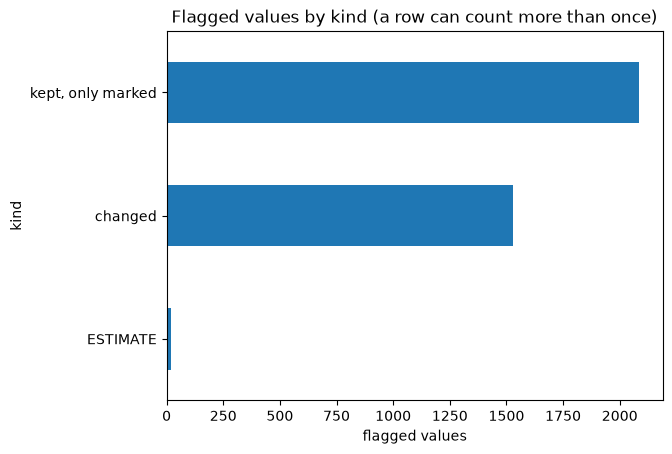

In [15]:
ax = quality.groupby("kind")["rows"].sum().plot(kind="barh", title="Flagged values by kind (a row can count more than once)")
ax.set_xlabel("flagged values");

**What the report says**

- **88.1% of the bookings (22,023) have no cleaning flag**: the cleaning touched a small part of the table.
- **1,419 rows (5.7%) have at least one changed value.** The largest groups are total prices recomputed from the PMS (466), CRM prices that were inflated (273) and `Undefined` meals (236).
- **Only 18 rows hold an ESTIMATE**: 15 week nights and 3 adr of 0-night stays.
- **1,781 rows are only marked**, so the analysis can include or exclude them. The largest groups are the children left empty (809) and the prices of 0 (377).

## 8. What to use in the analysis

- **Prices:** use only `price_ok` (price above 0, at least one night, not the outlier). There are 381 rows with adr 0 and 148 stays of 0 nights: they would pull every mean down.
- **Cancellations:** `is_canceled` is complete on all 25,000 rows, and counts `No-Show` as cancelled.
- **Lead time, segment, country:** these columns come only from the CRM, so they are missing on the 500 PMS-only rows.
- **People:** filter on `adults > 0` for per-person numbers (some bookings have only children).
- **Do not use as filters:** `date_inconsistent` describes the raw CRM (87 of its 88 rows are resolved in the merge), and the weekend nights are one day apart from the dates (README, "Known limits"), so there is no analysis by day of the week.
- **`agent_id` and `company_id`** are codes: count them, never average them.